In [1]:
from google.colab import drive
drive.mount('/content/gdrive')
root_path = 'gdrive/My Drive/Colab Notebooks/'

Mounted at /content/gdrive


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import LabelEncoder


# Load your CSV
df = pd.read_csv("/content/gdrive/MyDrive/Colab Notebooks/kholoud/merge of two sheets.csv")


# Initialize encoder
le = LabelEncoder()

# Fit and transform the 'position' column
df['DeMux configuration'] = le.fit_transform(df['position'])

# (Optional) drop original column if not needed
df = df.drop(columns=['position'])

# Split into design and performance columns
design_cols = [ 'g1(nm)', 'g2(nm)', 'g3(nm)', 'g4(nm)', 'l1(nm)', 'l2(nm)', 'l3(nm)', 'w(nm)', 'eps resonator', 'eps waveguide', 'CT 1(db)', 'CT 2(db)', 'Fw1 (nm)', 'Fw2 (nm)',  'DeMux configuration' ]
perf_cols = ['lam 1 max(nm)', 'P1 max',  'lam 2 max(nm)', 'P2 max']  # Customize as needed

X_design = df[design_cols].values
X_perf = df[perf_cols].values

# X_design_uni, idx = np.unique(X_design, axis=0, return_index=True)

# # Sort indices to maintain original order (optional)
# sorted_idx = np.sort(idx)

# # Use the same indices to filter B
# X_perf1 = X_perf[sorted_idx]

# # A_filtered is A without duplicates
# X_design1 = X_design[sorted_idx]

# Normalize both
design_scaler = MinMaxScaler()
perf_scaler = MinMaxScaler()

X_design_scaled = design_scaler.fit_transform(X_design)
X_perf_scaled = perf_scaler.fit_transform(X_perf)



# Train/test split
X_d_train, X_d_test, X_p_train, X_p_test = train_test_split(X_design_scaled, X_perf_scaled, test_size=0.2, random_state=42)

# # First split into train and temp (test + val)
# X_d_train, X_d_temp, X_p_train, X_p_temp = train_test_split(X_design_scaled, X_perf_scaled, test_size=0.3, random_state=42)

# # Split temp into val and test
# X_d_val, X_d_test, X_p_val, X_p_test = train_test_split(X_d_temp, X_p_temp, test_size=0.5, random_state=42)

# # Create PyTorch datasets
train_dataset = TensorDataset(torch.tensor(X_d_train, dtype=torch.float32),
                              torch.tensor(X_p_train, dtype=torch.float32))
test_dataset = TensorDataset(torch.tensor(X_d_test, dtype=torch.float32),
                             torch.tensor(X_p_test, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)



In [ ]:
print(dict(zip(le.classes_, le.transform(le.classes_))))


{'h': np.int64(0), 'h_with': np.int64(1), 'v': np.int64(2), 'v_with': np.int64(3)}


In [ ]:
df[design_cols].shape

(18856, 14)

In [ ]:
df[perf_cols].shape

(18856, 4)

In [ ]:
np.shape(X_design1)

(208, 15)

In [ ]:
np.shape(X_perf1)

(208, 4)

In [3]:
latent_dim = 16  #10 16
perf_dim = X_p_train.shape[1]
design_dim = X_d_train.shape[1]

# class Encoder(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.fc = nn.Sequential(
#             nn.Linear(design_dim + perf_dim, 64),
#             nn.ReLU(),
#             nn.Linear(64, 32),
#             nn.ReLU()
#         )
#         self.mu = nn.Linear(32, latent_dim)
#         self.logvar = nn.Linear(32, latent_dim)

#     def forward(self, x, c):
#         x = torch.cat([x, c], dim=1)
#         h = self.fc(x)
#         mu = self.mu(h)
#         logvar = self.logvar(h)
#         logvar = torch.clamp(logvar, min=-10, max=10)  # avoid NaNs
#         return mu, logvar

# class Decoder(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.fc = nn.Sequential(
#             nn.Linear(latent_dim + perf_dim, 32),
#             nn.ReLU(),
#             nn.Linear(32, 64),
#             nn.ReLU(),
#             nn.Linear(64, design_dim),
#             nn.Sigmoid()  # output between 0 and 1 (scale back later)
#         )

#     def forward(self, z, c):
#         x = torch.cat([z, c], dim=1)
#         return self.fc(x)

# class Encoder(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.fc = nn.Sequential(
#             nn.Linear(design_dim + perf_dim, 128),
#             nn.ReLU(),
#             nn.Linear(128, 64),
#             nn.ReLU(),
#             nn.Linear(64, 32),
#             nn.ReLU()
#         )
#         self.mu = nn.Linear(32, latent_dim)
#         self.logvar = nn.Linear(32, latent_dim)

#     def forward(self, x, c):
#         x = torch.cat([x, c], dim=1)
#         h = self.fc(x)
#         mu = self.mu(h)
#         logvar = self.logvar(h)
#         logvar = torch.clamp(logvar, min=-10, max=10)
#         return mu, logvar

# class Decoder(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.fc = nn.Sequential(
#             nn.Linear(latent_dim + perf_dim, 32),
#             nn.ReLU(),
#             nn.Linear(32, 64),
#             nn.ReLU(),
#             nn.Linear(64, 128),
#             nn.ReLU(),
#             nn.Linear(128, design_dim),
#             nn.Sigmoid()
#         )

#     def forward(self, z, c):
#         x = torch.cat([z, c], dim=1)
#         return self.fc(x)

import torch
from torch import nn

class Encoder(nn.Module):
    def __init__(self, design_dim, perf_dim, latent_dim):
        super().__init__()
        input_dim = design_dim + perf_dim

        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU()
        )

        self.mu = nn.Linear(64, latent_dim)
        self.logvar = nn.Linear(64, latent_dim)

    def forward(self, x, c):
        # Concatenate design and performance inputs
        x_cond = torch.cat([x, c], dim=1)
        hidden = self.net(x_cond)

        mu = self.mu(hidden)
        logvar = self.logvar(hidden)
        logvar = torch.clamp(logvar, min=-10, max=10)  # Prevent numerical issues

        return mu, logvar


class Decoder(nn.Module):
    def __init__(self, design_dim, perf_dim, latent_dim):
        super().__init__()
        input_dim = latent_dim + perf_dim

        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),

            nn.Linear(256, design_dim),
            nn.Sigmoid()  # Output between 0 and 1; scale back to original range outside model
        )

    def forward(self, z, c):
        # Concatenate latent vector with conditional input
        z_cond = torch.cat([z, c], dim=1)
        return self.net(z_cond)



class CVAE(nn.Module):
    def __init__(self, design_dim, perf_dim, latent_dim):
        super().__init__()
        self.encoder = Encoder(design_dim, perf_dim, latent_dim)
        self.decoder = Decoder(design_dim, perf_dim, latent_dim)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x, c):
        mu, logvar = self.encoder(x, c)
        z = self.reparameterize(mu, logvar)
        recon = self.decoder(z, c)
        return recon, mu, logvar

In [4]:
# # === STEP 3: Training ===
# model = CVAE()
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-4) #
# loss_fn = nn.MSELoss()

# def vae_loss(recon_x, x, mu, logvar):
#     recon_loss = loss_fn(recon_x, x)
#     kl_div = -0.5 * torch.mean(torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1))
#     return recon_loss # + kl_div * 1e-4

# epochs = 600
# for epoch in range(epochs):
#     model.train()
#     total_loss = 0
#     for x_batch, c_batch in train_loader:
#         optimizer.zero_grad()
#         recon, mu, logvar = model(x_batch, c_batch)
#         loss = vae_loss(recon, x_batch, mu, logvar)

#         if torch.isnan(loss):
#             print("NaN detected! Skipping batch.")
#             continue

#         loss.backward()
#         torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
#         optimizer.step()
#         total_loss += loss.item()

#     print(f"Epoch {epoch+1}/{epochs} - Loss: {total_loss:.4f}")

# === STEP 3: Training ===
model = CVAE(design_dim, perf_dim, latent_dim)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4) #
loss_fn = nn.MSELoss()

def vae_loss(recon_x, x, mu, logvar):
    recon_loss = loss_fn(recon_x, x)
    kl_div = -0.5 * torch.mean(torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1))
    return recon_loss # + kl_div * 1e-4

epochs = 600
for epoch in range(epochs):
    model.train()
    total_loss = 0
    for x_batch, c_batch in train_loader:
        optimizer.zero_grad()
        recon, mu, logvar = model(x_batch, c_batch)
        loss = vae_loss(recon, x_batch, mu, logvar)

        if torch.isnan(loss):
            print("NaN detected! Skipping batch.")
            continue

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs} - Loss: {total_loss:.4f}")

Epoch 1/600 - Loss: 14.6669
Epoch 2/600 - Loss: 5.8616
Epoch 3/600 - Loss: 3.9315
Epoch 4/600 - Loss: 3.0972
Epoch 5/600 - Loss: 2.6326
Epoch 6/600 - Loss: 2.4071
Epoch 7/600 - Loss: 2.2535
Epoch 8/600 - Loss: 2.0964
Epoch 9/600 - Loss: 1.9664
Epoch 10/600 - Loss: 1.8915
Epoch 11/600 - Loss: 1.8251
Epoch 12/600 - Loss: 1.7309
Epoch 13/600 - Loss: 1.6541
Epoch 14/600 - Loss: 1.5516
Epoch 15/600 - Loss: 1.4821
Epoch 16/600 - Loss: 1.4181
Epoch 17/600 - Loss: 1.3395
Epoch 18/600 - Loss: 1.2764
Epoch 19/600 - Loss: 1.2287
Epoch 20/600 - Loss: 1.1687
Epoch 21/600 - Loss: 1.1301
Epoch 22/600 - Loss: 1.0782
Epoch 23/600 - Loss: 1.0586
Epoch 24/600 - Loss: 0.9978
Epoch 25/600 - Loss: 0.9815
Epoch 26/600 - Loss: 0.9561
Epoch 27/600 - Loss: 0.9139
Epoch 28/600 - Loss: 0.9016
Epoch 29/600 - Loss: 0.8591
Epoch 30/600 - Loss: 0.8537
Epoch 31/600 - Loss: 0.8216
Epoch 32/600 - Loss: 0.8174
Epoch 33/600 - Loss: 0.7962
Epoch 34/600 - Loss: 0.7727
Epoch 35/600 - Loss: 0.7646
Epoch 36/600 - Loss: 0.7517


In [7]:
import matplotlib.pyplot as plt

model = CVAE(design_dim, perf_dim, latent_dim)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
loss_fn = nn.MSELoss()

train_losses = []   # store epoch losses

def vae_loss(recon_x, x, mu, logvar):
    recon_loss = loss_fn(recon_x, x)
    kl_div = -0.5 * torch.mean(torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1))
    return recon_loss   # + kl_div * 1e-4

epochs = 600

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for x_batch, c_batch in train_loader:
        optimizer.zero_grad()

        recon, mu, logvar = model(x_batch, c_batch)
        loss = vae_loss(recon, x_batch, mu, logvar)

        if torch.isnan(loss):
            continue

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item()

    epoch_loss = total_loss / len(train_loader)
    train_losses.append(epoch_loss)

    print(f"Epoch {epoch+1}/{epochs} - Loss: {epoch_loss:.6f}")

Epoch 1/600 - Loss: 0.062579
Epoch 2/600 - Loss: 0.022904
Epoch 3/600 - Loss: 0.015151
Epoch 4/600 - Loss: 0.011961
Epoch 5/600 - Loss: 0.010619
Epoch 6/600 - Loss: 0.009719
Epoch 7/600 - Loss: 0.009115
Epoch 8/600 - Loss: 0.008694
Epoch 9/600 - Loss: 0.008231
Epoch 10/600 - Loss: 0.007635
Epoch 11/600 - Loss: 0.007188
Epoch 12/600 - Loss: 0.006798
Epoch 13/600 - Loss: 0.006489
Epoch 14/600 - Loss: 0.006081
Epoch 15/600 - Loss: 0.005769
Epoch 16/600 - Loss: 0.005544
Epoch 17/600 - Loss: 0.005387
Epoch 18/600 - Loss: 0.005098
Epoch 19/600 - Loss: 0.004852
Epoch 20/600 - Loss: 0.004664
Epoch 21/600 - Loss: 0.004469
Epoch 22/600 - Loss: 0.004289
Epoch 23/600 - Loss: 0.004174
Epoch 24/600 - Loss: 0.003975
Epoch 25/600 - Loss: 0.003836
Epoch 26/600 - Loss: 0.003693
Epoch 27/600 - Loss: 0.003570
Epoch 28/600 - Loss: 0.003483
Epoch 29/600 - Loss: 0.003431
Epoch 30/600 - Loss: 0.003252
Epoch 31/600 - Loss: 0.003260
Epoch 32/600 - Loss: 0.003160
Epoch 33/600 - Loss: 0.003039
Epoch 34/600 - Loss

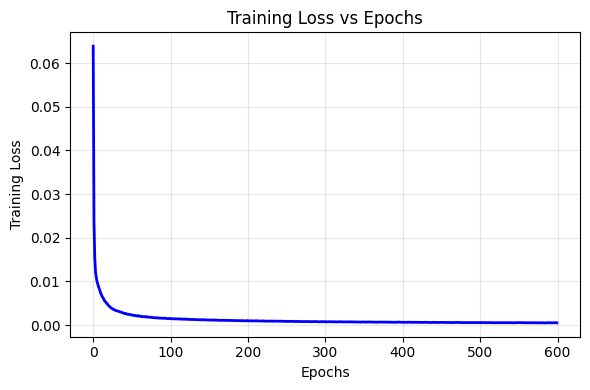

In [ ]:
plt.figure(figsize=(6,4))

plt.plot(train_losses, color='blue', linewidth=2)

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Training Loss vs Epochs")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

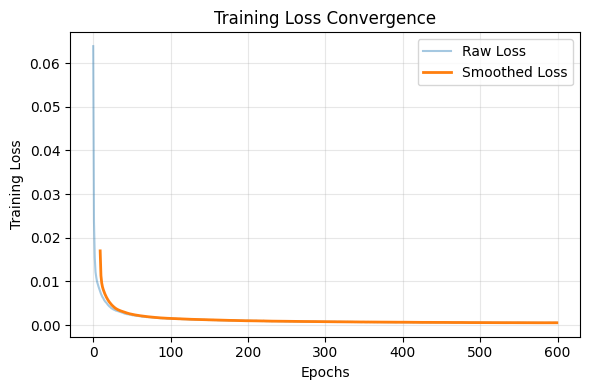

In [ ]:
import pandas as pd

smooth_loss = pd.Series(train_losses).rolling(window=10).mean()

plt.figure(figsize=(6,4))
plt.plot(train_losses, alpha=0.4, label="Raw Loss")
plt.plot(smooth_loss, linewidth=2, label="Smoothed Loss")

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("Training Loss Convergence")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
model.eval()
reconstructions = []
ground_truths = []
with torch.no_grad():
    for x_test, c_test in test_loader:
        recon, _, _ = model(x_test, c_test)
        reconstructions.append(recon)
        ground_truths.append(x_test)

# Stack all batches
reconstructed = torch.cat(reconstructions, dim=0).numpy()
true_designs = torch.cat(ground_truths, dim=0).numpy()

# Inverse transform to original scale
reconstructed_original = design_scaler.inverse_transform(reconstructed)
true_original = design_scaler.inverse_transform(true_designs)


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(true_original, reconstructed_original)
mse = mean_squared_error(true_original, reconstructed_original)

print(f"Test MAE: {mae:.4f}")
print(f"Test MSE: {mse:.4f}")


Test MAE: 0.5276
Test MSE: 1.7868


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(true_original, reconstructed_original)
mse = mean_squared_error(true_original, reconstructed_original)

print(f"Test MAE: {mae:.4f}")
print(f"Test MSE: {mse:.4f}")


Test MAE: 0.5352
Test MSE: 1.7112


In [ ]:
import pandas as pd
import numpy as np

# Let's look at the first 5 examples
num_examples = 5
sample_indices = np.arange(num_examples)

comparison_df = pd.DataFrame({
    "Feature": design_cols * num_examples,
    "True Design": true_original[sample_indices].flatten(),
    "Reconstructed Design": reconstructed_original[sample_indices].flatten(),
    "Sample": np.repeat(np.arange(num_examples), len(design_cols))
})

# Reshape for better readability
comparison_pivot = comparison_df.pivot(index="Feature", columns="Sample", values=["True Design", "Reconstructed Design"])
print(comparison_pivot)


                    True Design                                        \
Sample                        0           1            2            3   
Feature                                                                 
CT 1(db)             -23.500000  -15.300000     0.000000   -27.200001   
CT 2(db)             -19.200001  -21.900002   -35.699997    -0.000001   
DeMux configuration    3.000000    2.000000     1.000000     0.000000   
Fw1 (nm)              74.000000   40.000000    37.000000    19.000000   
Fw2 (nm)              39.000000  114.000000    25.000002    22.000000   
eps resonator          3.050000    1.000000     3.050000     1.000000   
eps waveguide          1.000000    1.000000     3.050000     1.000000   
g1(nm)                15.000000   10.000000    10.000000    10.000000   
g2(nm)                10.000000   10.000000    10.000000    10.000000   
g3(nm)                10.000000   10.000000    26.999998    10.000000   
g4(nm)                14.999999    5.000000    26.9

In [ ]:
# Get all performance values from test_loader
perf_inputs = []
with torch.no_grad():
    for _, c_test in test_loader:
        perf_inputs.append(c_test)
perf_all = torch.cat(perf_inputs, dim=0).numpy()
perf_original = perf_scaler.inverse_transform(perf_all)


In [ ]:
# Show the first 5 performance inputs
pd.DataFrame(perf_original[:5], columns=perf_cols)


,lam 1 max(nm),P1 max,lam 2 max(nm),P2 max
0,1680.000122,0.600,1270.0,0.600
1,980.000000,0.780,1400.0,0.510
2,1640.000000,0.520,1220.0,0.370
3,919.999939,0.420,1310.0,0.410
4,919.999939,0.431,1300.0,0.319


In [ ]:
import pandas as pd
import numpy as np

# Choose 5 samples to display
num_samples = 5
sample_indices = np.arange(num_samples)

# Get the first 5
true_x = true_original[sample_indices]
recon_x = reconstructed_original[sample_indices]
input_y = perf_original[sample_indices]  # this was created in previous step

# Combine into a DataFrame
rows = []
for i in range(num_samples):
    row = {
        "Sample": i,
        "Input Performance (Y)": np.round(input_y[i], 3).tolist(),
        "True Design (X)": np.round(true_x[i], 3).tolist(),
        "Reconstructed Design (X̂)": np.round(recon_x[i], 3).tolist()
    }
    rows.append(row)

comparison_df = pd.DataFrame(rows)

# Display
pd.set_option('display.max_colwidth', None)
print(comparison_df)


   Sample                                     Input Performance (Y)  \
0       0  [1680.0, 0.6000000238418579, 1270.0, 0.6000000238418579]   
1       1   [980.0, 0.7799999713897705, 1400.0, 0.5099999904632568]   
2       2  [1640.0, 0.5199999809265137, 1220.0, 0.3700000047683716]   
3       3  [920.0, 0.41999998688697815, 1310.0, 0.4099999964237213]   
4       4   [920.0, 0.4309999942779541, 1300.0, 0.3190000057220459]   

                                                                                                                         True Design (X)  \
0              [15.0, 10.0, 10.0, 15.0, 620.0, 620.0, 620.0, 160.0, 3.049999952316284, 1.0, -23.5, -19.200000762939453, 74.0, 39.0, 3.0]   
1              [10.0, 10.0, 10.0, 5.0, 620.0, 620.0, 620.0, 160.0, 1.0, 1.0, -15.300000190734863, -21.899999618530273, 40.0, 114.0, 2.0]   
2  [10.0, 10.0, 27.0, 27.0, 620.0, 890.0, 1075.0, 180.0, 3.049999952316284, 3.049999952316284, 0.0, -35.70000076293945, 37.0, 25.0, 1.0]   
3            

In [ ]:
X_d_test.shape

(3772, 15)

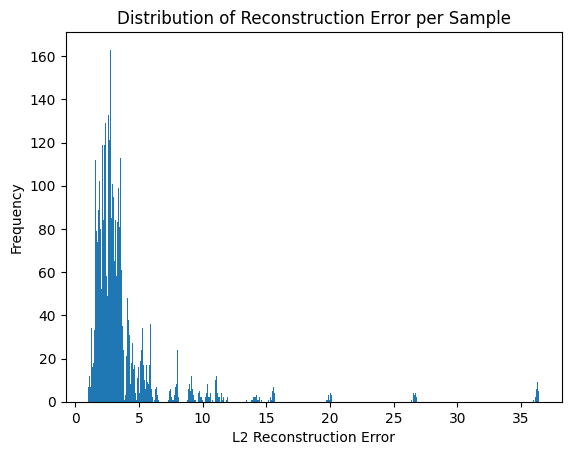

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Compute L2 error per sample
sample_errors = np.linalg.norm(true_original - reconstructed_original, axis=1)

plt.figure()
plt.hist(sample_errors, bins=500)
plt.xlabel("L2 Reconstruction Error")
plt.ylabel("Frequency")
plt.title("Distribution of Reconstruction Error per Sample")
plt.show()

Mean L2 Error: 3.7453356
Std L2 Error: 3.8347151
Max L2 Error: 36.436695
Min L2 Error: 1.020973


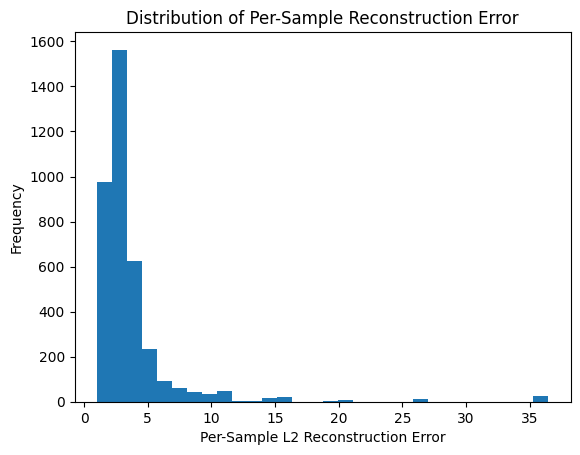

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Compute per-sample L2 error
sample_l2_errors = np.linalg.norm(
    true_original - reconstructed_original,
    axis=1
)

# Basic statistics
print("Mean L2 Error:", np.mean(sample_l2_errors))
print("Std L2 Error:", np.std(sample_l2_errors))
print("Max L2 Error:", np.max(sample_l2_errors))
print("Min L2 Error:", np.min(sample_l2_errors))

# Plot histogram
plt.figure()
plt.hist(sample_l2_errors, bins=30)
plt.xlabel("Per-Sample L2 Reconstruction Error")
plt.ylabel("Frequency")
plt.title("Distribution of Per-Sample Reconstruction Error")
plt.show()

Mean normalized error: 0.967041513062797
Std normalized error: 0.9901191998177782


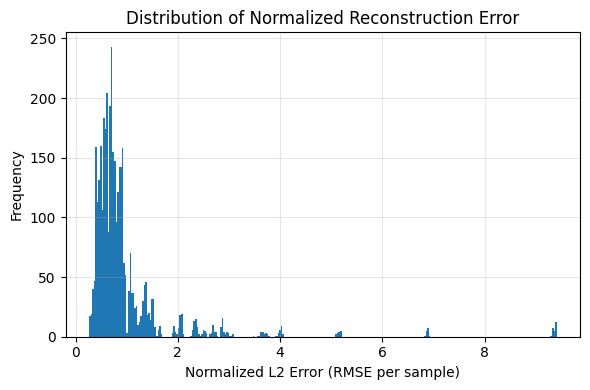

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# number of design parameters
d = true_original.shape[1]

# normalized per-sample L2 (RMSE per sample)
sample_errors_norm = np.linalg.norm(
    true_original - reconstructed_original,
    axis=1
) / np.sqrt(d)

print("Mean normalized error:", np.mean(sample_errors_norm))
print("Std normalized error:", np.std(sample_errors_norm))

plt.figure(figsize=(6,4))
plt.hist(sample_errors_norm, bins=300)
plt.xlabel("Normalized L2 Error (RMSE per sample)")
plt.ylabel("Frequency")
plt.title("Distribution of Normalized Reconstruction Error")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Mean range-normalized L2: 0.031192960079569693
Std range-normalized L2: 0.012602798064048635


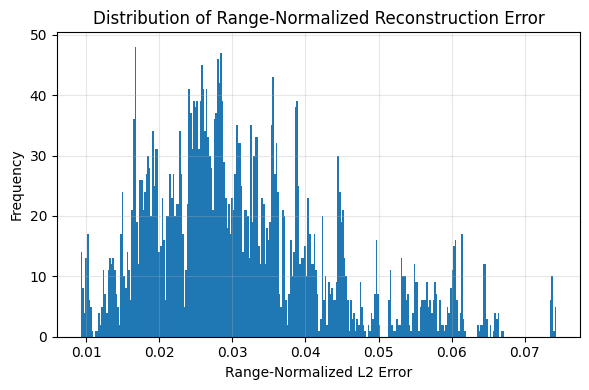

In [ ]:
# Get parameter ranges
param_range = design_scaler.data_max_ - design_scaler.data_min_

# Avoid division by zero
param_range[param_range == 0] = 1

# Compute normalized error per parameter
normalized_diff = (true_original - reconstructed_original) / param_range

# Compute L2 per sample in normalized space
sample_errors_range_norm = np.linalg.norm(normalized_diff, axis=1)

print("Mean range-normalized L2:", np.mean(sample_errors_range_norm))
print("Std range-normalized L2:", np.std(sample_errors_range_norm))

plt.figure(figsize=(6,4))
plt.hist(sample_errors_range_norm, bins=300)
plt.xlabel("Range-Normalized L2 Error")
plt.ylabel("Frequency")
plt.title("Distribution of Range-Normalized Reconstruction Error")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
for i, col in enumerate(design_cols):
    col_mae = mean_absolute_error(true_original[:, i], reconstructed_original[:, i])
    print(f"{col} MAE: {col_mae:.4f}")


g1(nm) MAE: 0.1214
g2(nm) MAE: 0.1382
g3(nm) MAE: 0.1884
g4(nm) MAE: 0.1768
l1(nm) MAE: 0.5950
l2(nm) MAE: 1.9308
l3(nm) MAE: 1.6264
w(nm) MAE: 0.2579
eps resonator MAE: 0.0023
eps waveguide MAE: 0.0009
CT 1(db) MAE: 0.3350
CT 2(db) MAE: 0.6280
Fw1 (nm) MAE: 0.9511
Fw2 (nm) MAE: 0.9595
DeMux configuration MAE: 0.0018


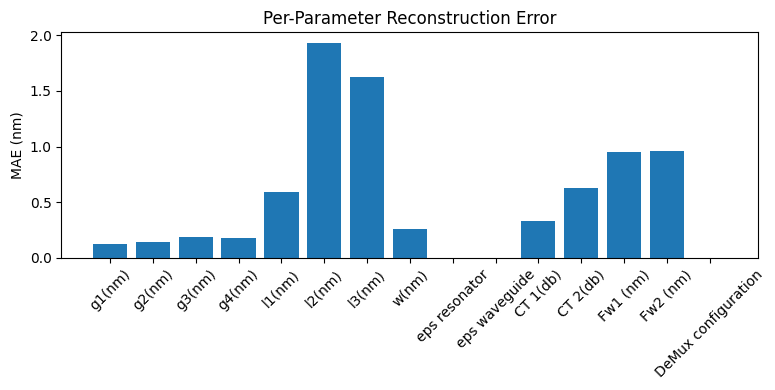

In [ ]:
param_mae = np.mean(np.abs(true_original - reconstructed_original), axis=0)

plt.figure(figsize=(8,4))
plt.bar(range(len(param_mae)), param_mae)
plt.xticks(range(len(param_mae)), design_cols, rotation=45)
plt.ylabel("MAE (nm)")
plt.title("Per-Parameter Reconstruction Error")
plt.tight_layout()
plt.show()

In [ ]:
model.eval()

all_mu = []

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

with torch.no_grad():
    for x_batch, c_batch in test_loader:
        x_batch = x_batch.to(device)
        c_batch = c_batch.to(device)

        mu, logvar = model.encoder(x_batch, c_batch)
        all_mu.append(mu.cpu().numpy())

z_mu = np.concatenate(all_mu, axis=0)

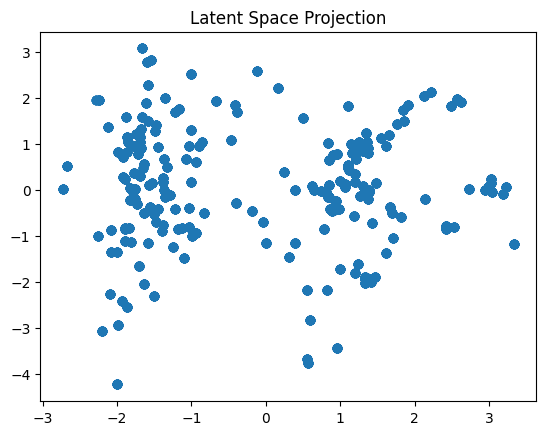

In [ ]:
from sklearn.decomposition import PCA

#z_mu = mu_values_from_encoder  # collect from test set

pca = PCA(n_components=2)
z_2d = pca.fit_transform(z_mu)

plt.scatter(z_2d[:,0], z_2d[:,1])
plt.title("Latent Space Projection")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Get the index of 'position_encoded' from design_cols
position_idx = design_cols.index('position_encoded')

# Extract the 'position_encoded' values for the test set samples
# true_original contains the inverse-transformed design parameters for the test set
position_encoded_test = true_original[:, position_idx]

# Create the scatter plot
plt.figure(figsize=(8, 6))
scatter = plt.scatter(z_2d[:, 0], z_2d[:, 1], c=position_encoded_test, cmap='Set1', s=50, alpha=0.2) #viridis

# Add a color bar
cbar = plt.colorbar(scatter)
cbar.set_label('DeMux configuration_encoded')

# Set tick labels for the color bar using the LabelEncoder classes
# First, get unique encoded values and their corresponding original labels
unique_encoded_positions = np.unique(position_encoded_test).astype(int)
original_labels = le.inverse_transform(unique_encoded_positions)

cbar.set_ticks(unique_encoded_positions)
cbar.set_ticklabels(original_labels)

plt.title('Latent Space Projection colored by DeMUX configuration')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.show()

ValueError: 'position_encoded' is not in list

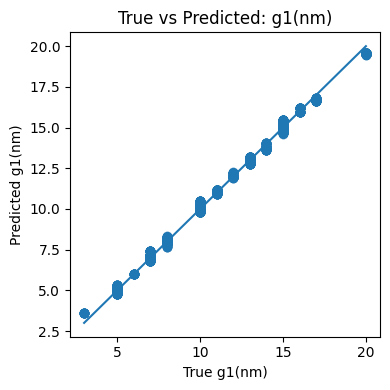

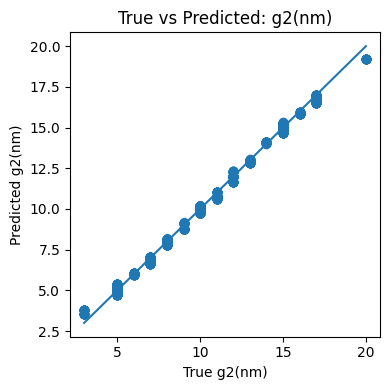

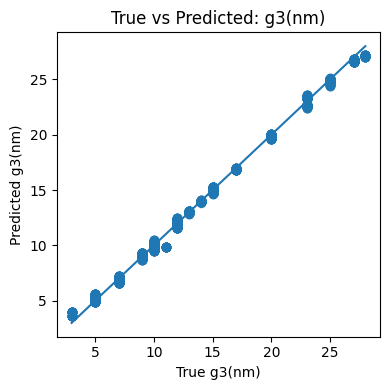

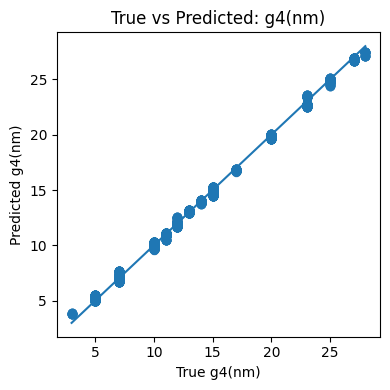

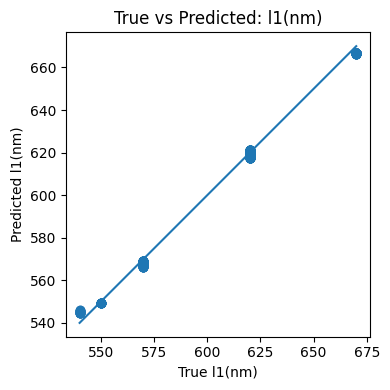

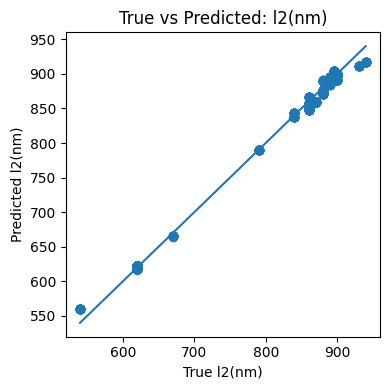

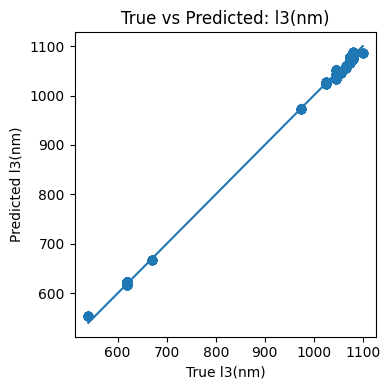

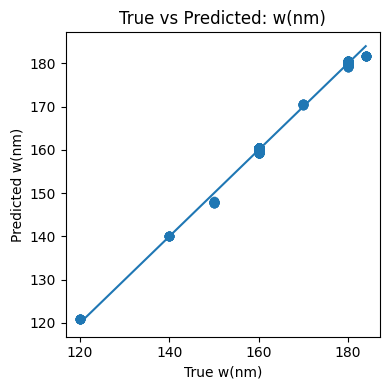

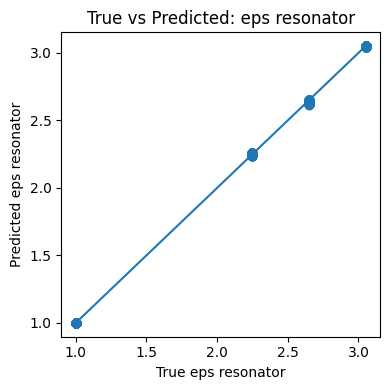

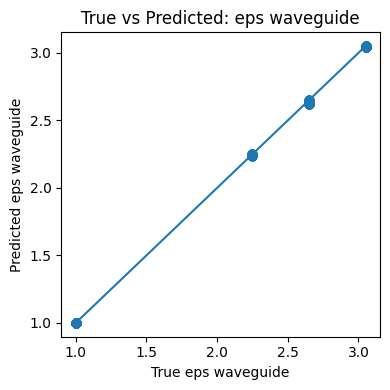

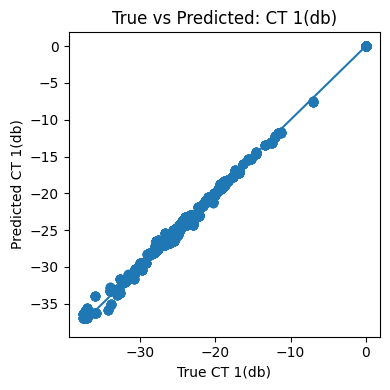

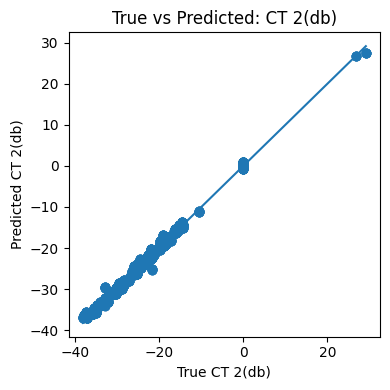

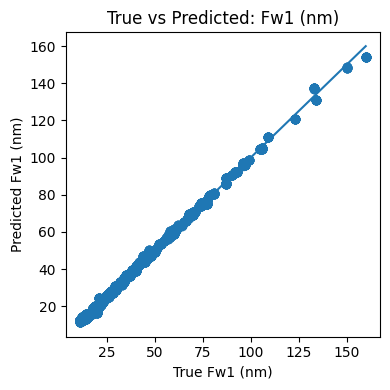

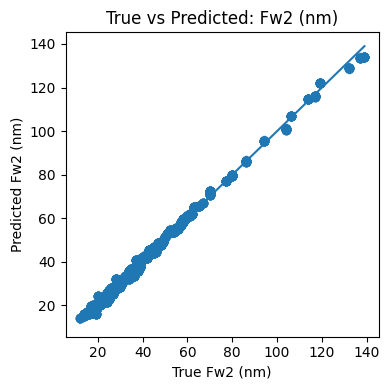

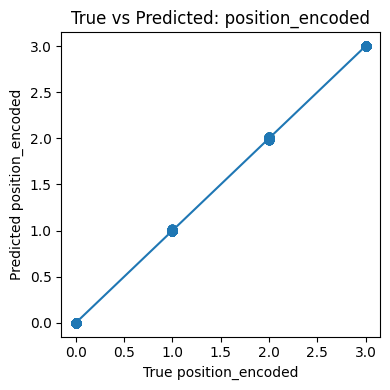

In [ ]:
for i, param in enumerate(design_cols):
    plt.figure(figsize=(4,4))

    plt.scatter(
        true_original[:, i],
        reconstructed_original[:, i],
        alpha=0.5
    )

    # Diagonal reference
    min_val = min(true_original[:, i].min(),
                  reconstructed_original[:, i].min())
    max_val = max(true_original[:, i].max(),
                  reconstructed_original[:, i].max())

    plt.plot([min_val, max_val],
             [min_val, max_val])

    plt.xlabel(f"True {param}")
    plt.ylabel(f"Predicted {param}")
    plt.title(f"True vs Predicted: {param}")
    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np

n = len(design_cols)
cols = 4
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(3*cols, 3*rows))
axes = axes.flatten()

for i, param in enumerate(design_cols):
    ax = axes[i]

    ax.scatter(true_original[:, i], reconstructed_original[:, i], alpha=0.5)

    min_val = min(true_original[:, i].min(),
                  reconstructed_original[:, i].min())
    max_val = max(true_original[:, i].max(),
                  reconstructed_original[:, i].max())

    ax.plot([min_val, max_val], [min_val, max_val])

    ax.set_xlabel(f"True {param}")
    ax.set_ylabel(f"Predicted {param}")
    ax.set_title(param)

plt.tight_layout()
plt.show()

In [ ]:
model.eval()
num_samples = 20

generated_designs = []

with torch.no_grad():
    for _ in range(num_samples):
        z = torch.randn(1, latent_dim).to(device)
        generated = decoder(z, target_c)
        generated_designs.append(generated.cpu().numpy())

generated_designs = np.vstack(generated_designs)

NameError: name 'decoder' is not defined

figures

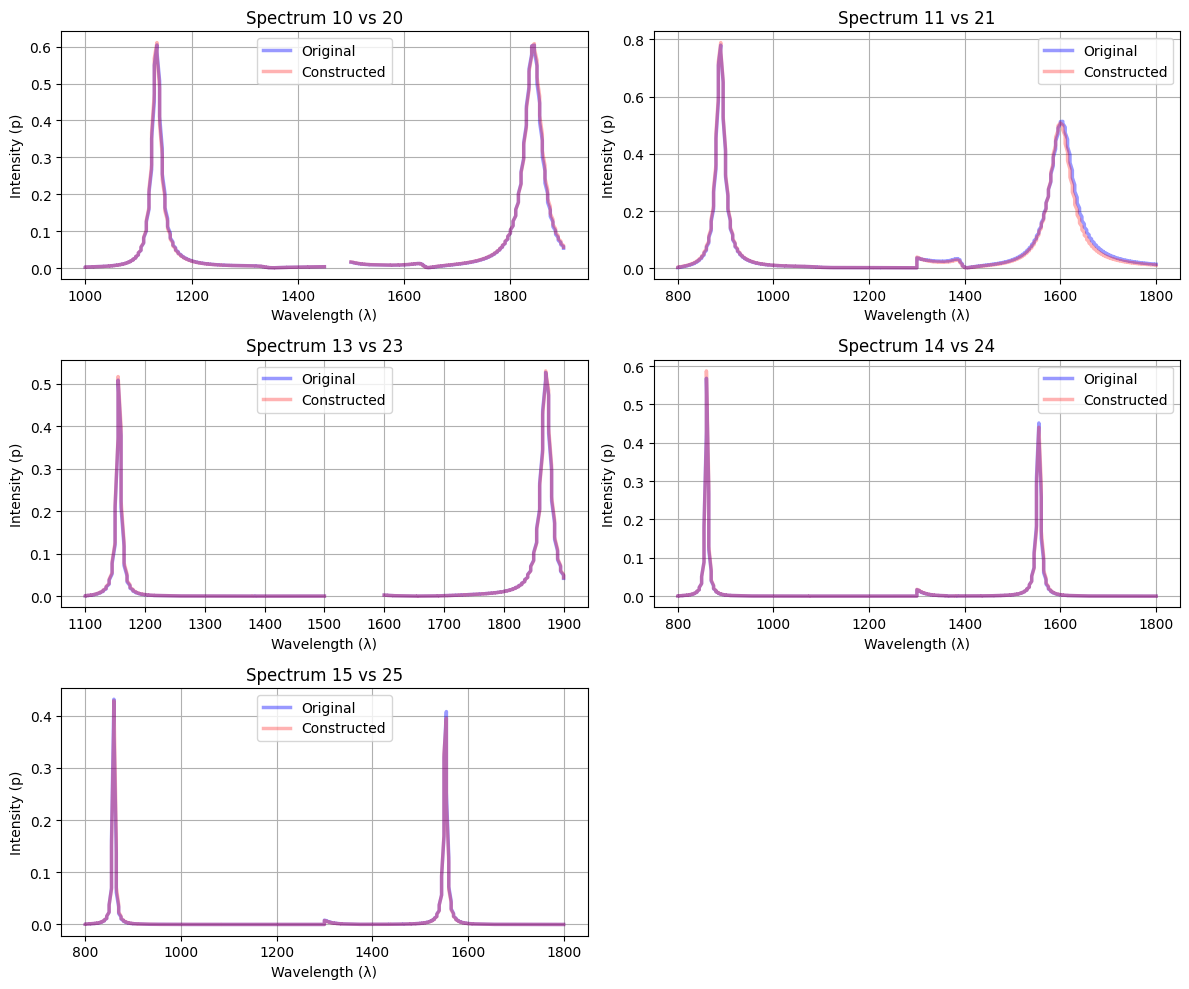

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Read CSV files ---
original = pd.read_csv('/content/gdrive/MyDrive/Colab Notebooks/kholoud/original copy.csv')
constructed = pd.read_csv('/content/gdrive/MyDrive/Colab Notebooks/kholoud/reconstructed copy.csv')

# --- Define the five spectral groups ---
groups = {
    '10_20': ['lam 10', 'p 10', 'lam 20', 'p20'],
    '11_21': ['lam 11', 'p 11', 'lam 21', 'p21'],
    '13_23': ['lam 13', 'p 13', 'lam 23', 'p23'],
    '14_24': ['lam 14', 'p 14', 'lam 24', 'p24'],
    '15_25': ['lam 15', 'p 15', 'lam 25', 'p25']
}

# --- Helper to build continuous spectrum from columns ---
def build_spectrum(df, lam1, p1, lam2, p2):
    lam = pd.concat([df[lam1], df[lam2]]).sort_values().values
    p = pd.concat([df[p1], df[p2]]).values
    return pd.DataFrame({'wavelength': lam, 'intensity': p})

# --- Plot setup ---
plt.figure(figsize=(12, 10))

for i, (label, cols) in enumerate(groups.items(), 1):
    lam1, p1, lam2, p2 = cols

    # Extract spectra
    spec_orig = build_spectrum(original, lam1, p1, lam2, p2)
    spec_const = build_spectrum(constructed, lam1, p1, lam2, p2)

    # --- Subplot for each group ---
    plt.subplot(3, 2, i)
    plt.plot(spec_orig['wavelength'], spec_orig['intensity'],
             label='Original', color='blue', linewidth=2.5, alpha=0.4)
    plt.plot(spec_const['wavelength'], spec_const['intensity'],
             label='Constructed', color='red',  linewidth=2.5, alpha=0.3)  #linestyle='--',

    plt.title(f'Spectrum {label.replace("_", " vs ")}')
    plt.xlabel('Wavelength (λ)')
    plt.ylabel('Intensity (p)')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()





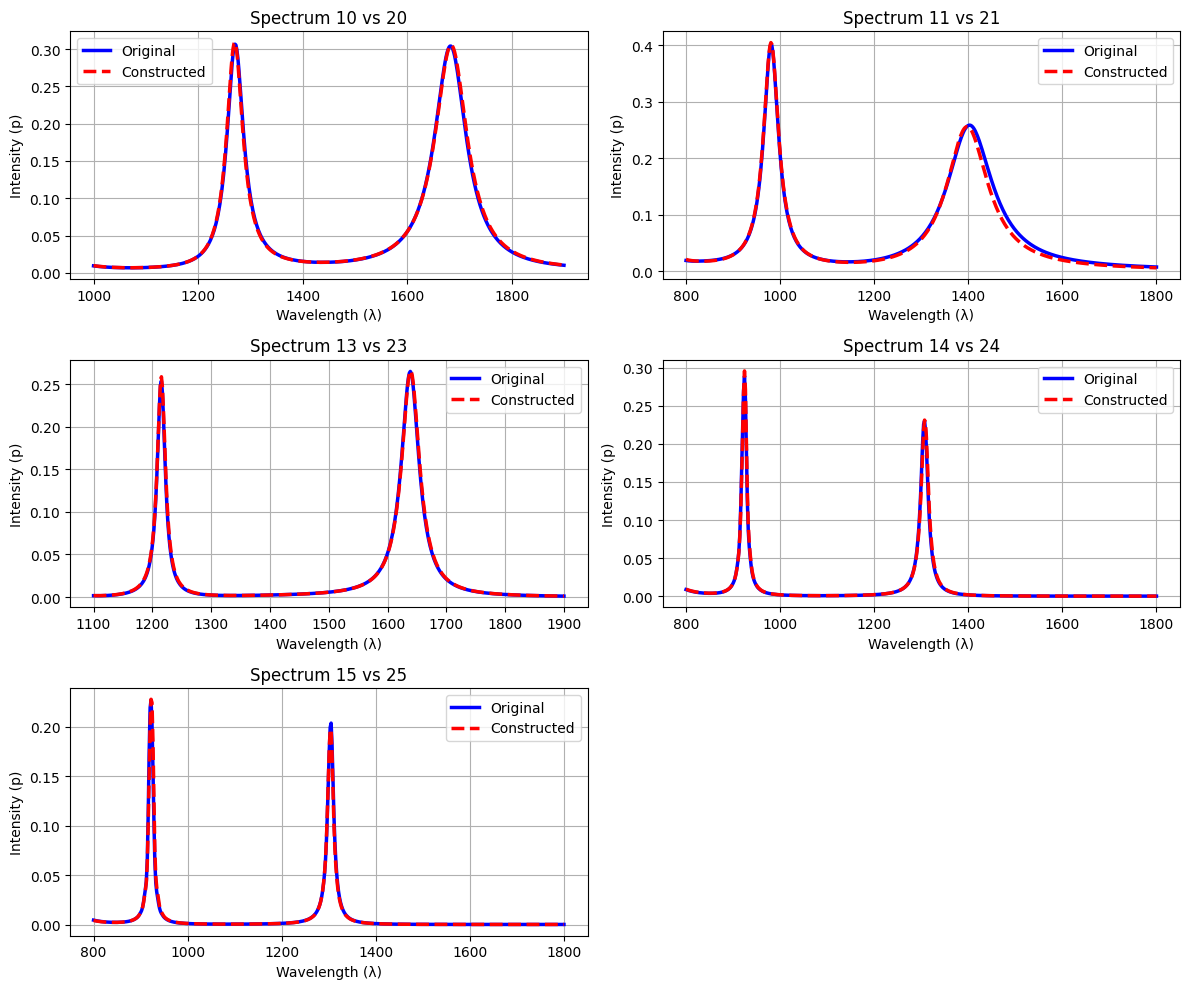

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline
import numpy as np

# --- Read CSV files ---
original = pd.read_csv('/content/gdrive/MyDrive/Colab Notebooks/kholoud/original copy.csv')
constructed = pd.read_csv('/content/gdrive/MyDrive/Colab Notebooks/kholoud/reconstructed copy.csv')

# --- Define the five spectral groups ---
groups = {
    '10_20': ['lam 10', 'p 10', 'lam 20', 'p20'],
    '11_21': ['lam 11', 'p 11', 'lam 21', 'p21'],
    '13_23': ['lam 13', 'p 13', 'lam 23', 'p23'],
    '14_24': ['lam 14', 'p 14', 'lam 24', 'p24'],
    '15_25': ['lam 15', 'p 15', 'lam 25', 'p25']
}

# --- Helper function to build a continuous spectrum ---
def build_spectrum(df, lam1, p1, lam2, p2):
    # Create DataFrames for each lam/p pair
    df1 = df[[lam1, p1]].rename(columns={lam1:'wavelength', p1:'intensity'}).dropna()
    df2 = df[[lam2, p2]].rename(columns={lam2:'wavelength', p2:'intensity'}).dropna()

    # Concatenate
    spec = pd.concat([df1, df2], ignore_index=True)

    # Handle duplicate wavelengths by averaging intensity
    spec = spec.groupby('wavelength')['intensity'].mean().reset_index()

    # Sort by wavelength
    spec = spec.sort_values('wavelength')

    return spec


# --- Plot all five spectra ---
plt.figure(figsize=(12, 10))

for i, (label, cols) in enumerate(groups.items(), 1):
    lam1, p1, lam2, p2 = cols

    spec_orig = build_spectrum(original, lam1, p1, lam2, p2)
    spec_const = build_spectrum(constructed, lam1, p1, lam2, p2)

    # Smooth interpolation with 500 points
    # Ensure there are enough unique points for spline interpolation
    if len(spec_orig['wavelength']) > 3:
        lam_orig_smooth = np.linspace(spec_orig['wavelength'].min(), spec_orig['wavelength'].max(), 500)
        spline_orig = make_interp_spline(spec_orig['wavelength'], spec_orig['intensity'], k=min(3, len(spec_orig['wavelength']) - 1))
        intensity_orig_smooth = spline_orig(lam_orig_smooth)
    else:
        lam_orig_smooth = spec_orig['wavelength']
        intensity_orig_smooth = spec_orig['intensity']

    if len(spec_const['wavelength']) > 3:
        lam_const_smooth = np.linspace(spec_const['wavelength'].min(), spec_const['wavelength'].max(), 500)
        spline_const = make_interp_spline(spec_const['wavelength'], spec_const['intensity'], k=min(3, len(spec_const['wavelength']) - 1))
        intensity_const_smooth = spline_const(lam_const_smooth)
    else:
        lam_const_smooth = spec_const['wavelength']
        intensity_const_smooth = spec_const['intensity']


    # --- Plot each spectral group ---
    plt.subplot(3, 2, i)
    plt.plot(lam_orig_smooth, intensity_orig_smooth,
             label='Original', color='blue', linewidth=2.5)
    plt.plot(lam_const_smooth, intensity_const_smooth,
             label='Constructed', color='red', linestyle='--', linewidth=2.5)

    plt.title(f'Spectrum {label.replace("_", " vs ")}')
    plt.xlabel('Wavelength (λ)')
    plt.ylabel('Intensity (p)')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

/tmp/ipython-input-552005121.py:63: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


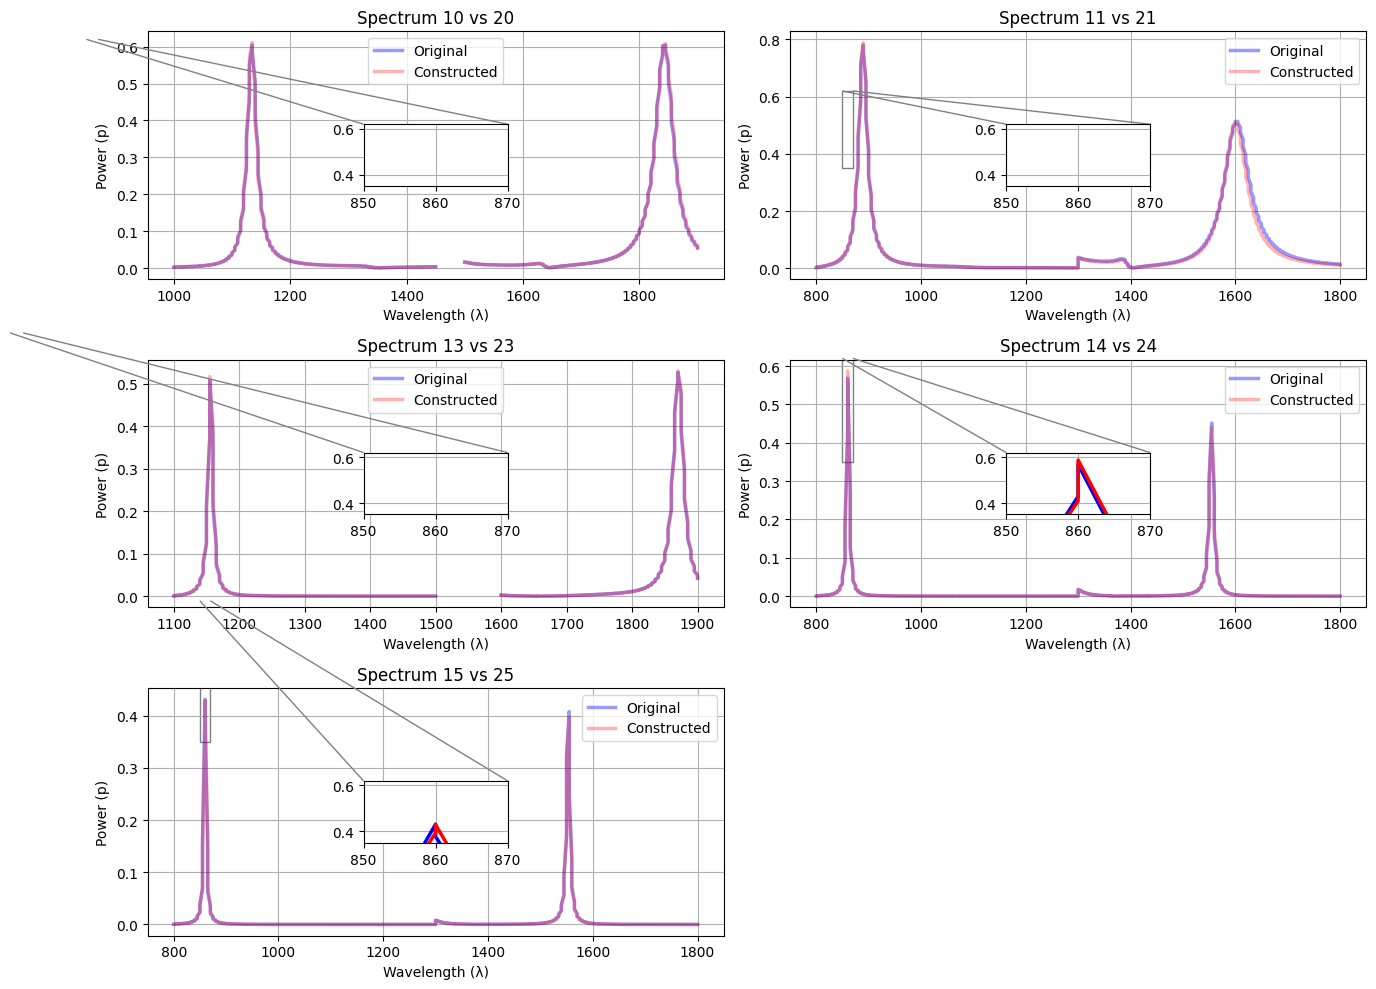

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# --- Read CSV files ---
original = pd.read_csv('/content/gdrive/MyDrive/Colab Notebooks/kholoud/original copy.csv')
constructed = pd.read_csv('/content/gdrive/MyDrive/Colab Notebooks/kholoud/reconstructed copy.csv')

# --- Define the five spectral groups ---
groups = {
    '10_20': ['lam 10', 'p 10', 'lam 20', 'p20'],
    '11_21': ['lam 11', 'p 11', 'lam 21', 'p21'],
    '13_23': ['lam 13', 'p 13', 'lam 23', 'p23'],
    '14_24': ['lam 14', 'p 14', 'lam 24', 'p24'],
    '15_25': ['lam 15', 'p 15', 'lam 25', 'p25']
}

# --- Helper: combine two lam/p pairs into one continuous spectrum ---
def build_spectrum(df, lam1, p1, lam2, p2):
    lam = pd.concat([df[lam1], df[lam2]]).sort_values().values
    p = pd.concat([df[p1], df[p2]]).values
    return pd.DataFrame({'wavelength': lam, 'power': p})

# --- Create figure with subplots ---
plt.figure(figsize=(13, 10))

for i, (label, cols) in enumerate(groups.items(), 1):
    lam1, p1, lam2, p2 = cols

    # Extract spectra
    spec_orig = build_spectrum(original, lam1, p1, lam2, p2)
    spec_const = build_spectrum(constructed, lam1, p1, lam2, p2)

    # --- Subplot for each spectrum group ---
    ax = plt.subplot(3, 2, i)
    ax.plot(spec_orig['wavelength'], spec_orig['power'],
            label='Original', color='blue', linewidth=2.5, alpha=0.4)
    ax.plot(spec_const['wavelength'], spec_const['power'],
            label='Constructed', color='red', linestyle='-', linewidth=2.5, alpha=0.3)

    ax.set_title(f"Spectrum {label.replace('_', ' vs ')}")
    ax.set_xlabel("Wavelength (λ)")
    ax.set_ylabel("Power (p)")
    ax.legend()
    ax.grid(True)

    # --- Create a zoomed inset inside each subplot ---
    axins = inset_axes(ax, width="25%", height="25%", loc='center')

    axins.plot(spec_orig['wavelength'], spec_orig['power'], color='blue', linewidth=2.5)
    axins.plot(spec_const['wavelength'], spec_const['power'], color='red', linewidth=2.5)

    # Define your zoom range (adjust to fit your data)
    x1, x2 = 115, 870    # wavelength zoom range
    y1, y2 = 0.35, 0.62    # intensity zoom range
    axins.set_xlim(x1, x2)
    axins.set_ylim(y1, y2)
    axins.grid(True)

    # Draw a rectangle showing the zoomed region
    mark_inset(ax, axins, loc1=2, loc2=1, fc="none", ec="0.5")  # 1 , 3  .1

plt.tight_layout()
plt.show()

/tmp/ipython-input-883405267.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


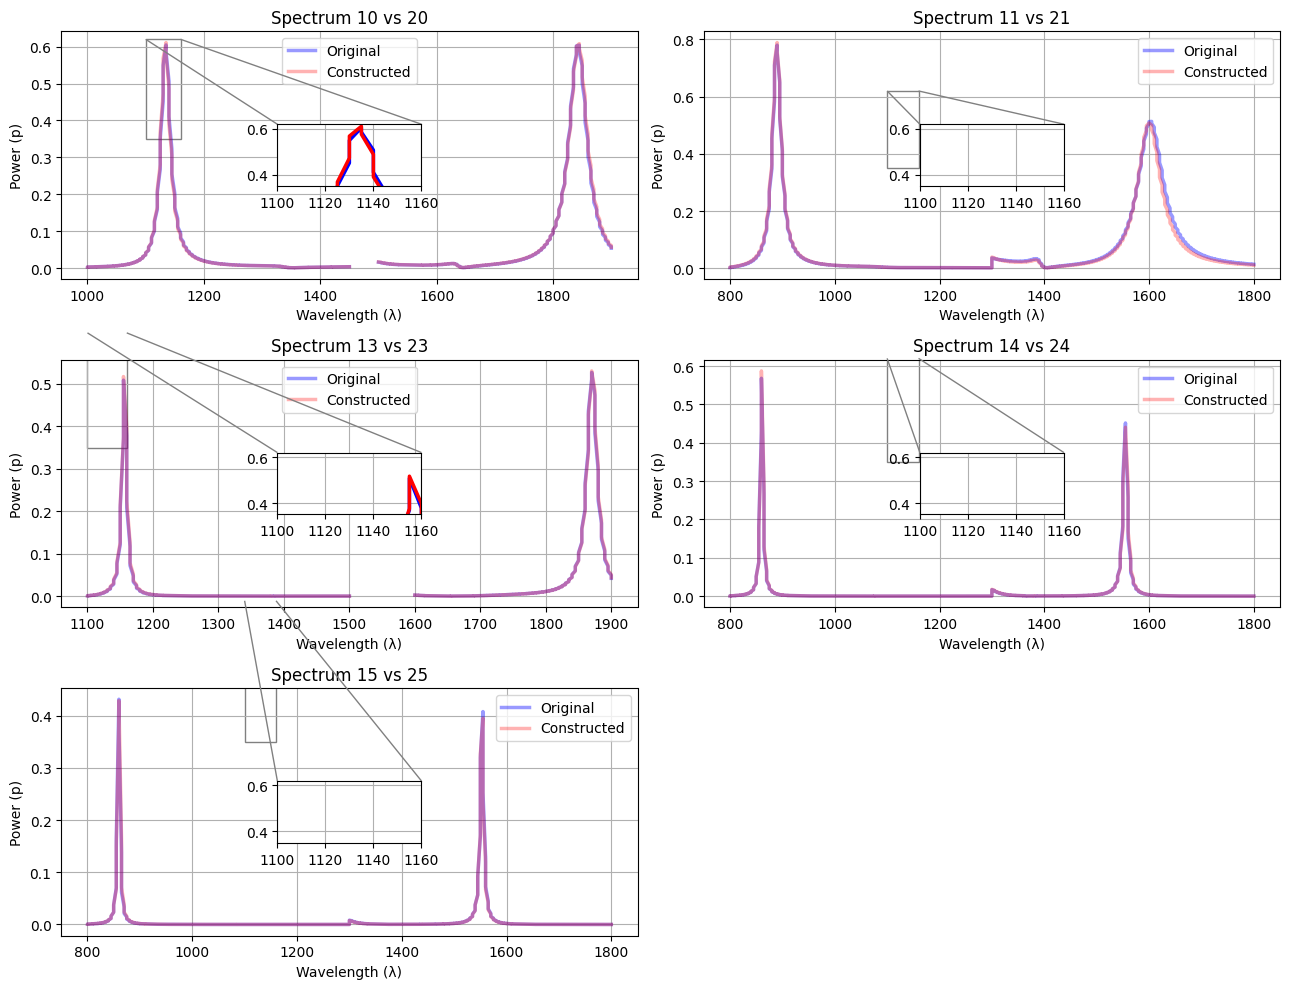

In [ ]:
# --- b2a version ---
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
import matplotlib.ticker as ticker

# --- Read CSV files ---
original = pd.read_csv('/content/gdrive/MyDrive/Colab Notebooks/kholoud/original copy.csv')
constructed = pd.read_csv('/content/gdrive/MyDrive/Colab Notebooks/kholoud/reconstructed copy.csv')

# --- Define the five spectral groups ---
groups = {
    '10_20': ['lam 10', 'p 10', 'lam 20', 'p20'],
    '11_21': ['lam 11', 'p 11', 'lam 21', 'p21'],
    '13_23': ['lam 13', 'p 13', 'lam 23', 'p23'],
    '14_24': ['lam 14', 'p 14', 'lam 24', 'p24'],
    '15_25': ['lam 15', 'p 15', 'lam 25', 'p25']
}

# --- Helper: combine two lam/p pairs into one continuous spectrum ---
def build_spectrum(df, lam1, p1, lam2, p2):
    lam = pd.concat([df[lam1], df[lam2]]).sort_values().values
    p = pd.concat([df[p1], df[p2]]).values
    return pd.DataFrame({'wavelength': lam, 'power': p})

# --- Create figure with subplots ---
plt.figure(figsize=(13, 10))

for i, (label, cols) in enumerate(groups.items(), 1):
    lam1, p1, lam2, p2 = cols

    # Extract spectra
    spec_orig = build_spectrum(original, lam1, p1, lam2, p2)
    spec_const = build_spectrum(constructed, lam1, p1, lam2, p2)

    # --- Subplot for each spectrum group ---
    ax = plt.subplot(3, 2, i)
    ax.plot(spec_orig['wavelength'], spec_orig['power'],
            label='Original', color='blue', linewidth=2.5, alpha=0.4)
    ax.plot(spec_const['wavelength'], spec_const['power'],
            label='Constructed', color='red', linestyle='-', linewidth=2.5, alpha=0.3)

    ax.set_title(f"Spectrum {label.replace('_', ' vs ')}")
    ax.set_xlabel("Wavelength (λ)")
    ax.set_ylabel("Power (p)")
    ax.legend()
    ax.grid(True)

    # --- Create a zoomed inset inside each subplot ---
    axins = inset_axes(ax, width="25%", height="25%", loc='center')

    axins.plot(spec_orig['wavelength'], spec_orig['power'], color='blue', linewidth=2.5)
    axins.plot(spec_const['wavelength'], spec_const['power'], color='red', linewidth=2.5)

    # Define your zoom range (adjust to fit your data)
    x1, x2 = 1100, 1160    # wavelength zoom range
    y1, y2 = 0.35, 0.62  # intensity zoom range
    axins.set_xlim(x1, x2)
    axins.set_ylim(y1, y2)
    axins.grid(True)

    # --- Control tick step size in inset axes ---
    #axins.yaxis.set_major_locator(ticker.MultipleLocator(0.03))   # Y-axis step of 0.05
    #axins.xaxis.set_major_locator(ticker.MultipleLocator(100))    # X-axis step of 100 (optional)

    # Draw a rectangle showing the zoomed region
    mark_inset(ax, axins, loc1=2, loc2=1, fc="none", ec="0.5")

plt.tight_layout()
plt.show()
